# Eclipse Analytics | NBA Shot Success — Modeling Comparison

**Goal:** Predict whether an NBA field-goal attempt is made using information available at shot release. Compare a prevalence baseline, Logistic Regression, Random Forest, and XGBoost. Report confusion matrices, accuracy, precision, recall, F1, ROC-AUC, log loss, and Brier score.

**Input:** `shotdetail_2025 (1).tar.xz` (2025–26 regular-season archive). Keep this archive beside this notebook. All figures and CSV reports are generated locally.

**Methodology:** Split by **game date** chronologically (70% / 15% / 15% of dates) to prevent shots from the same game appearing in multiple splits. Fit preprocessing on training data only. Select a model using validation-set log loss, then report its test-set performance. No post-shot fields such as `EVENT_TYPE`, and no full-season shooting averages, are inputs.

**Install packages if needed (Terminal):** `python3 -m pip install notebook pandas numpy matplotlib scikit-learn xgboost` (prefer a virtual environment).

## 1. Imports and load dataset

In [1]:
%pip install scikit-learn xgboost

You should consider upgrading via the '/Users/aarav/Desktop/EclipseBasketball/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import tarfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, brier_score_loss, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay, roc_curve)
from xgboost import XGBClassifier
from IPython.display import display

pd.set_option('display.max_columns', 40)
ROOT = Path.cwd()
archive = ROOT / 'shotdetail_2025 (1).tar.xz'
if not archive.exists():
    candidates = [p for p in ROOT.glob('shotdetail_2025*.tar.xz') if '_po_' not in p.name]
    if not candidates:
        raise FileNotFoundError('Put the 2025–26 regular-season shotdetail_2025 archive in this folder.')
    archive = candidates[0]
with tarfile.open(archive, 'r:xz') as tf:
    csv_members = [m for m in tf.getmembers() if m.isfile() and m.name.endswith('.csv')]
    if len(csv_members) != 1:
        raise ValueError('Expected exactly one CSV inside the source archive')
    df = pd.read_csv(tf.extractfile(csv_members[0]), dtype={'GAME_ID':str, 'PLAYER_ID':str},
                     parse_dates=['GAME_DATE'])
print('Source:', archive.name)
print('Rows, columns:', df.shape)
display(df.head(3))

Source: shotdetail_2025 (1).tar.xz
Rows, columns: (219160, 24)


,GRID_TYPE,GAME_ID,GAME_EVENT_ID,PLAYER_ID,PLAYER_NAME,TEAM_ID,TEAM_NAME,PERIOD,MINUTES_REMAINING,SECONDS_REMAINING,EVENT_TYPE,ACTION_TYPE,SHOT_TYPE,SHOT_ZONE_BASIC,SHOT_ZONE_AREA,SHOT_ZONE_RANGE,SHOT_DISTANCE,LOC_X,LOC_Y,SHOT_ATTEMPTED_FLAG,SHOT_MADE_FLAG,GAME_DATE,HTM,VTM
0,Shot Chart Detail,22500014,7,1629638,Nickeil Alexander-Walker,1610612737,Atlanta Hawks,1,11,43,Missed Shot,Jump Shot,3PT Field Goal,Above the Break 3,Right Side Center(RC),24+ ft.,26,175,202,1,0,2026-01-19,ATL,MIL
1,Shot Chart Detail,22500014,10,1630700,Dyson Daniels,1610612737,Atlanta Hawks,1,11,27,Made Shot,Driving Layup Shot,2PT Field Goal,Restricted Area,Center(C),Less Than 8 ft.,1,-4,12,1,1,2026-01-19,ATL,MIL
2,Shot Chart Detail,22500014,13,1630700,Dyson Daniels,1610612737,Atlanta Hawks,1,10,59,Missed Shot,Jump Shot,3PT Field Goal,Right Corner 3,Right Side(R),24+ ft.,24,238,71,1,0,2026-01-19,ATL,MIL


## 2. Validation, target, and input features

`SHOT_MADE_FLAG` is the binary outcome. `EVENT_TYPE` reveals the label and must not be used. `ACTION_TYPE` may contain retrospective annotation and is excluded conservatively. Player/team IDs, date, and game ID are used only for grouping or splitting, not as raw predictors. This first benchmark uses location, shot type/zone, and period clock; historical player and defensive features are a possible next experiment.

In [3]:
assert set(df['SHOT_MADE_FLAG'].dropna().unique()) == {0, 1}
assert df['SHOT_DISTANCE'].ge(0).all()
assert not df.duplicated(['GAME_ID','GAME_EVENT_ID']).any()
print('Missing values in original source:', int(df.isna().sum().sum()))
print('Exact duplicated rows:', int(df.duplicated().sum()))

# Derive features available by shot release
df['TIME_REMAINING_SECONDS'] = df['MINUTES_REMAINING'] * 60 + df['SECONDS_REMAINING']
df['IS_THREE'] = df['SHOT_TYPE'].eq('3PT Field Goal').astype(int)
df['IS_OVERTIME'] = df['PERIOD'].gt(4).astype(int)
numeric_features = ['SHOT_DISTANCE','LOC_X','LOC_Y','PERIOD',
                    'TIME_REMAINING_SECONDS','IS_THREE','IS_OVERTIME']
categorical_features = ['SHOT_ZONE_BASIC','SHOT_ZONE_AREA']
features = numeric_features + categorical_features
target = 'SHOT_MADE_FLAG'
assert not {'EVENT_TYPE','ACTION_TYPE','SHOT_MADE_FLAG'}.intersection(features)
print('Selected input columns:', features)
display(df[features + [target]].head())

Missing values in original source: 0
Exact duplicated rows: 0
Selected input columns: ['SHOT_DISTANCE', 'LOC_X', 'LOC_Y', 'PERIOD', 'TIME_REMAINING_SECONDS', 'IS_THREE', 'IS_OVERTIME', 'SHOT_ZONE_BASIC', 'SHOT_ZONE_AREA']


,SHOT_DISTANCE,LOC_X,LOC_Y,PERIOD,TIME_REMAINING_SECONDS,IS_THREE,IS_OVERTIME,SHOT_ZONE_BASIC,SHOT_ZONE_AREA,SHOT_MADE_FLAG
0,26,175,202,1,703,1,0,Above the Break 3,Right Side Center(RC),0
1,1,-4,12,1,687,0,0,Restricted Area,Center(C),1
2,24,238,71,1,659,1,0,Right Corner 3,Right Side(R),0
3,2,-10,22,1,625,0,0,Restricted Area,Center(C),1
4,1,7,12,1,599,0,0,Restricted Area,Center(C),1


## 3. Chronological train / validation / test split

We split **unique game dates**, not individual shots. Date-based splitting helps simulate predicting later games and keeps games together. Some dates contain multiple games, so the shot counts will not be exactly 70/15/15. The test split should not drive model selection.

In [4]:
df = df.sort_values(['GAME_DATE','GAME_ID','GAME_EVENT_ID']).reset_index(drop=True)
dates = np.sort(df['GAME_DATE'].unique())
train_end = dates[int(len(dates)*0.70)-1]
val_end = dates[int(len(dates)*0.85)-1]
df['split'] = np.where(df['GAME_DATE'] <= train_end, 'train',
                       np.where(df['GAME_DATE'] <= val_end, 'validation', 'test'))
assert df.groupby('GAME_ID')['split'].nunique().eq(1).all()
summary = df.groupby('split').agg(shots=(target,'size'),games=('GAME_ID','nunique'),
                                  first_date=('GAME_DATE','min'),last_date=('GAME_DATE','max'),
                                  make_rate=(target,'mean')).reindex(['train','validation','test'])
display(summary)
train = df['split'].eq('train')
validation = df['split'].eq('validation')
test = df['split'].eq('test')
X_train, y_train = df.loc[train, features], df.loc[train,target].astype(int)
X_val, y_val = df.loc[validation,features], df.loc[validation,target].astype(int)
X_test, y_test = df.loc[test,features], df.loc[test,target].astype(int)

,shots,games,first_date,last_date,make_rate
split,,,,,
train,149547,838,2025-10-21,2026-02-20,0.468903
validation,33483,189,2026-02-21,2026-03-17,0.469163
test,36130,203,2026-03-18,2026-04-12,0.481456


## 4. Train the four approaches

The **prevalence baseline** assigns every shot the training-set make rate. The other three algorithms get identical predictors and splits. Numeric variables are median-imputed and scaled; categorical values are one-hot encoded, with transformations fitted on training data only. Hyperparameters are fixed before examining the test results, not optimized on the test split.

In [5]:
def make_preprocessor():
    return ColumnTransformer([
        ('numeric', Pipeline([('impute', SimpleImputer(strategy='median')),
                              ('scale', StandardScaler())]), numeric_features),
        ('category', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ], sparse_threshold=0)

model_specs = {
    'Logistic Regression': LogisticRegression(max_iter=500, solver='lbfgs'),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=14,
                       min_samples_leaf=20, max_features='sqrt', random_state=42, n_jobs=4),
    'XGBoost': XGBClassifier(n_estimators=170, max_depth=5, learning_rate=.07,
                   subsample=.85, colsample_bytree=.85, objective='binary:logistic',
                   eval_metric='logloss', tree_method='hist', n_jobs=4, random_state=42)
}
trained_models = {}
probabilities = {}
train_prevalence = float(y_train.mean())
for name, estimator in model_specs.items():
    pipeline = Pipeline([('preprocess', make_preprocessor()), ('model', estimator)])
    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline
    probabilities[(name, 'validation')] = pipeline.predict_proba(X_val)[:,1]
    probabilities[(name, 'test')] = pipeline.predict_proba(X_test)[:,1]
    print('Trained:', name)
for split, labels in [('validation',y_val),('test',y_test)]:
    probabilities[('Prevalence baseline',split)] = np.full(len(labels),train_prevalence)
print('Training-set shot make rate:',f'{train_prevalence:.2%}')

Trained: Logistic Regression
Trained: Random Forest
Trained: XGBoost
Training-set shot make rate: 46.89%


## 5. Summary metrics and confusion matrices

**Accuracy** = share correctly classified at threshold 0.50. **Precision** = fraction of predicted makes that were makes. **Recall** = fraction of actual makes identified. **F1** balances precision and recall. **ROC-AUC** assesses ranking of makes vs misses; **log loss** and **Brier score** assess probability quality (lower is better). TN/FP/FN/TP show the numbers of correctly and incorrectly predicted makes/misses.

In [6]:
def evaluate(name, split, labels, proba):
    prediction = (proba >= 0.50).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels,prediction,labels=[0,1]).ravel()
    return {'Model':name,'Split':split,'N':len(labels),
            'Accuracy':accuracy_score(labels,prediction),
            'Precision':precision_score(labels,prediction,zero_division=0),
            'Recall':recall_score(labels,prediction,zero_division=0),
            'F1':f1_score(labels,prediction,zero_division=0),
            'ROC-AUC':roc_auc_score(labels,proba),
            'Log Loss':log_loss(labels,proba),
            'Brier Score':brier_score_loss(labels,proba),
            'TN':tn,'FP':fp,'FN':fn,'TP':tp}

metrics=[]
for split, labels in [('validation',y_val),('test',y_test)]:
    for name in ['Prevalence baseline', *model_specs.keys()]:
        metrics.append(evaluate(name,split,labels,probabilities[(name,split)]))
results = pd.DataFrame(metrics)
cols=['Model','Accuracy','Precision','Recall','F1','ROC-AUC','Log Loss','Brier Score']
print('VALIDATION RESULTS (used for model selection):')
display(results.loc[results.Split.eq('validation'),cols].round(4))
print('HELD-OUT TEST RESULTS (descriptive evaluation):')
display(results.loc[results.Split.eq('test'),cols].round(4))
print('CONFUSION-MATRIX COUNTS ON TEST SET:')
display(results.loc[results.Split.eq('test'),['Model','TN','FP','FN','TP']])

VALIDATION RESULTS (used for model selection):


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Log Loss,Brier Score
0,Prevalence baseline,0.5308,0.0000,0.0000,0.0000,0.5000,0.6912,0.2490
1,Logistic Regression,0.6298,0.6746,0.4076,0.5082,0.6476,0.6538,0.2307
2,Random Forest,0.6292,0.6779,0.3992,0.5025,0.6513,0.6476,0.2281
3,XGBoost,0.6296,0.6787,0.3998,0.5032,0.6500,0.6479,0.2283


HELD-OUT TEST RESULTS (descriptive evaluation):


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Log Loss,Brier Score
4,Prevalence baseline,0.5185,0.0000,0.0000,0.0000,0.5000,0.6928,0.2498
5,Logistic Regression,0.6248,0.6785,0.4196,0.5185,0.6470,0.6558,0.2317
6,Random Forest,0.6247,0.6809,0.4148,0.5155,0.6533,0.6488,0.2287
7,XGBoost,0.6255,0.6831,0.4145,0.5159,0.6539,0.6486,0.2286


CONFUSION-MATRIX COUNTS ON TEST SET:


,Model,TN,FP,FN,TP
4,Prevalence baseline,18735,0,17395,0
5,Logistic Regression,15276,3459,10096,7299
6,Random Forest,15354,3381,10180,7215
7,XGBoost,15390,3345,10185,7210


## 6. Visual comparisons

Report all three classifiers; do not equate high accuracy with good probability forecasts. A common 0.50 threshold can result in relatively low recall for made shots when shots are difficult to predict individually.

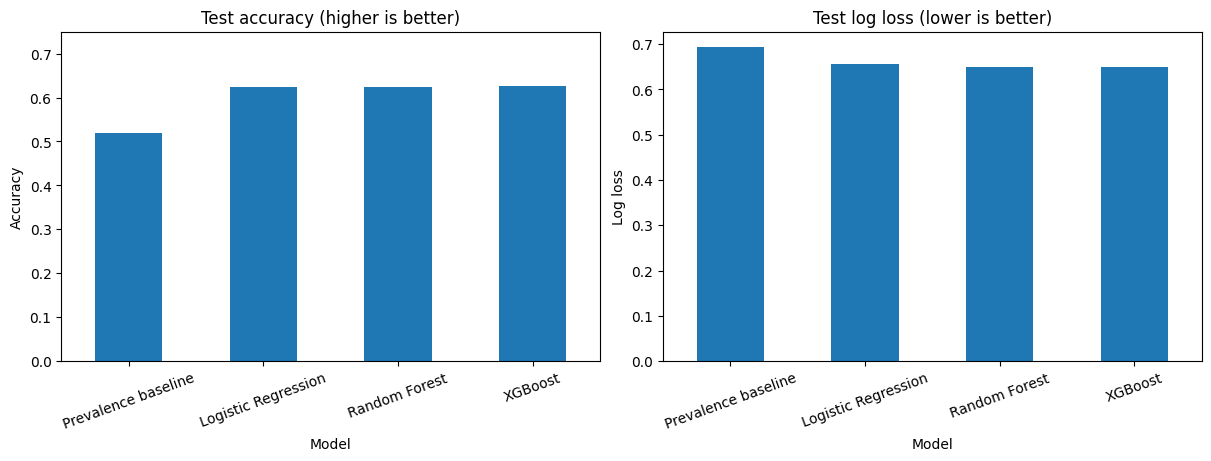

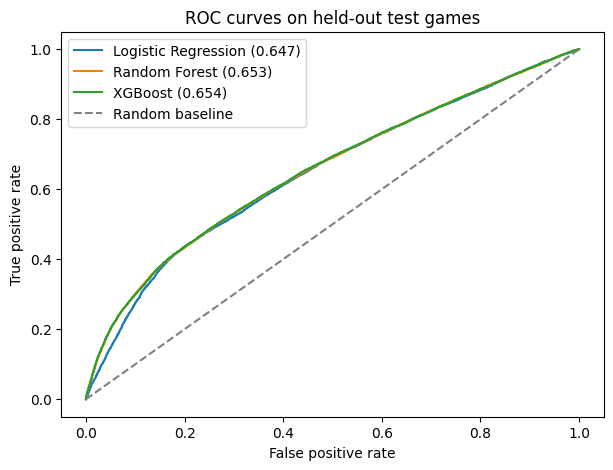

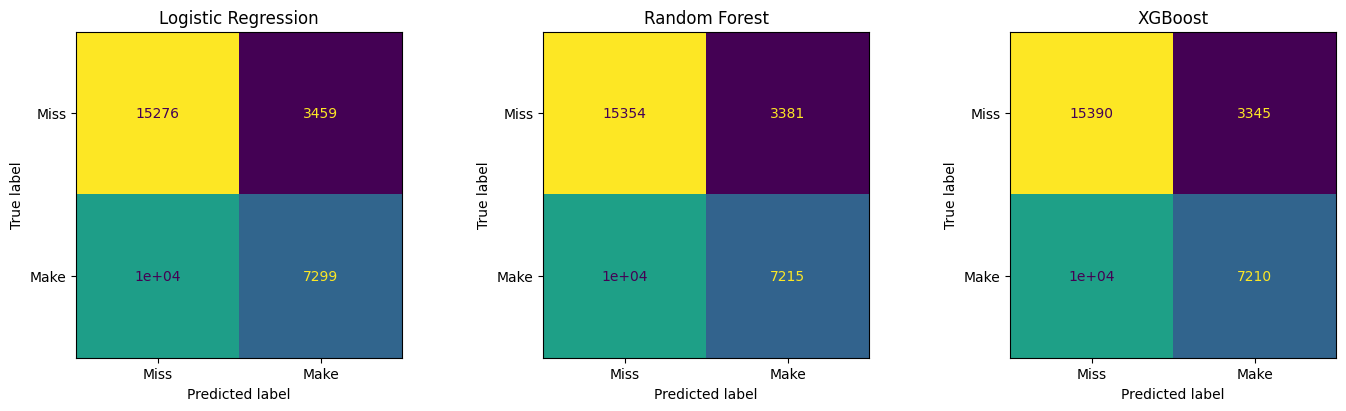

In [7]:
test_results = results[results.Split.eq('test')].set_index('Model')
fig, axes = plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True)
test_results['Accuracy'].plot.bar(ax=axes[0],rot=20,title='Test accuracy (higher is better)')
axes[0].set_ylim(0, 0.75);axes[0].set_ylabel('Accuracy')
test_results['Log Loss'].plot.bar(ax=axes[1],rot=20,title='Test log loss (lower is better)')
axes[1].set_ylabel('Log loss')
plt.show()
fig,ax=plt.subplots(figsize=(7,5))
for name in model_specs:
    fpr,tpr,_=roc_curve(y_test,probabilities[(name,'test')])
    ax.plot(fpr,tpr,label=f"{name} ({roc_auc_score(y_test, probabilities[(name,'test')]):.3f})")
ax.plot([0,1],[0,1],'--',color='gray',label='Random baseline')
ax.set(title='ROC curves on held-out test games',xlabel='False positive rate',ylabel='True positive rate')
ax.legend();plt.show()
fig,axes=plt.subplots(1,3,figsize=(14,4),constrained_layout=True)
for ax,name in zip(axes,model_specs):
    cm=confusion_matrix(y_test,probabilities[(name,'test')]>=0.5,labels=[0,1])
    ConfusionMatrixDisplay(cm,display_labels=['Miss','Make']).plot(ax=ax,colorbar=False)
    ax.set_title(name)
plt.show()

## 7. Choose a model using validation log loss

This selection rule was specified before the test comparison. If two models are nearly tied, we should describe the difference as small and consider uncertainty, model complexity, and interpretability. A test win in one metric is not a reason to override the validation choice.

In [8]:
validation_results=results[results.Split.eq('validation') & results.Model.ne('Prevalence baseline')]
selected_name = validation_results.sort_values('Log Loss').iloc[0]['Model']
selected_val = validation_results.set_index('Model').loc[selected_name]
selected_test = test_results.loc[selected_name]
print('SELECTED MODEL:',selected_name)
print('Validation log loss:',round(selected_val['Log Loss'],6))
print('Test accuracy:',f"{selected_test['Accuracy']:.2%}")
print('Test ROC-AUC:',round(selected_test['ROC-AUC'],4))
print('Test log loss:',round(selected_test['Log Loss'],4))

SELECTED MODEL: Random Forest
Validation log loss: 0.647592
Test accuracy: 62.47%
Test ROC-AUC: 0.6533
Test log loss: 0.6488


### Discussion-ready interpretation

Using the **2025–26 regular season only**, all three learned models meaningfully outperform the training-prevalence baseline. With these selected shot-location and time features, the three models are very close in classification accuracy. We choose **Random Forest** based on the **lowest validation log loss**, not the best-looking test metric. This edge is small and does **not** establish that Random Forest is universally superior. XGBoost slightly outperforms Random Forest in **test ROC-AUC**, illustrating why a single metric is not enough.

**What the positive class means:** “make.” Precision answers *when we predict a make, how often is it actually made?* Recall answers *of the actual makes, how many did we find?* The false negatives (missed makes) are relatively numerous at the fixed 0.50 decision threshold. For probability estimation, log loss and calibration are more important than raw accuracy alone.

**Caveats:** These results apply only to the 2025–26 regular season. They do not incorporate defender distance, matchups, or true shot-clock time; `TIME_REMAINING_SECONDS` represents the **period clock**. `SHOT_TYPE` and zone labels are assumed known by shot release, and should be checked for availability in the intended application. These findings are not causal. For final modeling, compare on Hayden's combined dataset and historical player/opponent features using the **same date split** across models, then repeat model selection. Keep the final test set sealed during tuning.

## 8. Export results for GitHub and the team

In [9]:
results.to_csv(ROOT/'nba_model_comparison_metrics.csv',index=False)
print('Saved',ROOT/'nba_model_comparison_metrics.csv')
print('Share the .ipynb notebook + small metrics CSV in a pull request; do not upload your .venv or the entire raw archive unless the team requests it.')

Saved /Users/aarav/Downloads/EclipseBasketball_Starter/nba_model_comparison_metrics.csv
Share the .ipynb notebook + small metrics CSV in a pull request; do not upload your .venv or the entire raw archive unless the team requests it.
